# 09 Results review

**Objective.** Final top 10s with intervals, component breakdowns, robustness badges, sanity checks and reserves for the Unstop check.

**Inputs.** final_rankings CSVs and stage tables.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from common import style
from common.io import read_parquet, read_table
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
%matplotlib inline

## Step 1. Top 10 batters

In [2]:
from final_rankings import plots as p6
from common.config import ROOT
tb = pd.read_csv(ROOT / "final_rankings" / "top10_batters.csv")
tb

,rank,player_id,player_name,teams,comp_types_played,total_balls,pressure_balls,matches_with_pressure,prism,prism_p10,prism_p90,median_rank,rank_lo80,rank_hi80,p_top10,consistency_index,robust_share,robust_badge
0,1,6396,Tim David,"Australia, Mumbai Indians, Royal Challengers B...","IPL, T20I_associate, T20I_full",1154,331,53,70.3967,43.0350,98.0730,2.0,1.0,9.0,0.920,0.7273,1.0000,True
1,2,50284,Vaibhav Sooryavanshi,"Rajasthan Royals, India, India A","Emerging, IPL, T20I_full",659,103,14,68.3469,46.3957,87.6429,2.5,1.0,8.1,0.934,0.8889,0.6000,False
2,3,6281,Abhishek Sharma,"Sunrisers Hyderabad, India, India A","Emerging, IPL, T20I_associate, T20I_full",2250,321,40,52.9842,36.3287,67.0585,6.0,2.0,14.0,0.806,0.7826,0.9333,True
3,4,5553,Phil Salt,"England, Royal Challengers Bengaluru, Kolkata ...","IPL, T20I_full",1582,230,28,53.1963,31.3879,72.4638,6.0,2.0,19.0,0.754,0.6154,0.9333,True
4,5,2756,Shashank Singh,"Punjab Kings, Sunrisers Hyderabad",IPL,555,126,22,48.2920,22.7786,73.4712,7.0,2.0,28.1,0.660,0.8000,0.6667,False
5,6,6726,Romario Shepherd,"West Indies, Royal Challengers Bengaluru, Sunr...","IPL, T20I_full",657,171,30,44.3748,23.4214,66.5932,9.0,3.0,26.1,0.560,0.6154,0.8667,True
6,7,838,Glenn Maxwell,"Australia, Royal Challengers Bengaluru, Punjab...","IPL, T20I_full",903,194,31,40.4129,-5.6314,69.1548,14.0,2.0,72.2,0.424,0.5556,0.8667,True
7,8,1699,Suryakumar Yadav,"India, Mumbai Indians","IPL, T20I_associate, T20I_full",2646,528,59,36.1629,18.9467,50.5587,15.0,7.0,33.0,0.276,0.6000,0.8000,True
8,9,4708,Rinku Singh,"Kolkata Knight Riders, India","IPL, T20I_full",1230,257,40,36.8139,16.8889,52.9076,15.0,5.0,35.0,0.296,0.7692,0.4000,False
9,10,4260,Heinrich Klaasen,"Sunrisers Hyderabad, South Africa","IPL, T20I_full",1401,199,34,34.6399,15.6149,49.9851,16.0,6.0,36.0,0.274,0.9091,0.3333,False


## Step 2. Top 10 bowlers

In [3]:
tw = pd.read_csv(ROOT / "final_rankings" / "top10_bowlers.csv")
tw

,rank,player_id,player_name,teams,comp_types_played,total_balls,pressure_balls,matches_with_pressure,prism,prism_p10,prism_p90,median_rank,rank_lo80,rank_hi80,p_top10,consistency_index,robust_share,robust_badge
0,1,781,Sunil Narine,Kolkata Knight Riders,IPL,1482,280,27,43.0043,28.8408,57.8669,2.0,1.0,7.0,0.954,0.7895,0.9286,True
1,2,830,Josh Hazlewood,"Royal Challengers Bengaluru, Australia","IPL, T20I_full",1368,362,36,35.0335,14.2145,56.7988,4.0,1.0,22.0,0.758,0.6667,1.0000,True
2,3,2933,Jasprit Bumrah,"Mumbai Indians, India","IPL, T20I_associate, T20I_full",1630,360,41,30.1460,17.2246,41.6524,6.0,2.0,17.0,0.740,0.5200,0.9286,True
3,4,4722,Rashid Khan,"Gujarat Titans, Afghanistan","IPL, T20I_associate, T20I_full",2651,448,62,28.3253,11.4189,44.6247,8.0,2.0,26.0,0.608,0.6000,0.9286,True
4,5,7920,Nathan Ellis,"Australia, Punjab Kings, Chennai Super Kings","IPL, T20I_full",858,241,25,23.9747,10.4355,36.6916,10.0,3.0,29.0,0.502,0.6250,0.7857,False
5,6,6523,Blessing Muzarabani,"Zimbabwe, Kolkata Knight Riders","IPL, T20I_full",820,191,24,25.6157,8.6368,39.3245,10.0,3.0,30.0,0.512,0.4375,0.9286,True
6,7,4219,Krunal Pandya,"Lucknow Super Giants, Royal Challengers Bengaluru",IPL,1227,221,22,24.3402,6.1162,43.7870,10.0,2.0,36.1,0.516,0.6667,0.7857,False
7,8,8661,Matheesha Pathirana,"Chennai Super Kings, Sri Lanka, Kolkata Knight...","IPL, T20I_full",1031,313,32,22.4669,4.9175,39.4869,12.0,3.0,38.0,0.456,0.5556,0.8571,True
8,9,6256,Varun Chakravarthy,"Kolkata Knight Riders, India","IPL, T20I_associate, T20I_full",2080,374,37,21.7502,8.8784,34.3496,13.0,4.0,30.1,0.410,0.7143,0.9286,True
9,10,4900,Wanindu Hasaranga,"Sri Lanka, Royal Challengers Bengaluru, Rajast...","IPL, T20I_associate, T20I_full",1950,388,44,18.3790,7.1182,30.4888,15.0,6.0,34.0,0.292,0.4000,0.2857,False


## Step 3. Component breakdowns

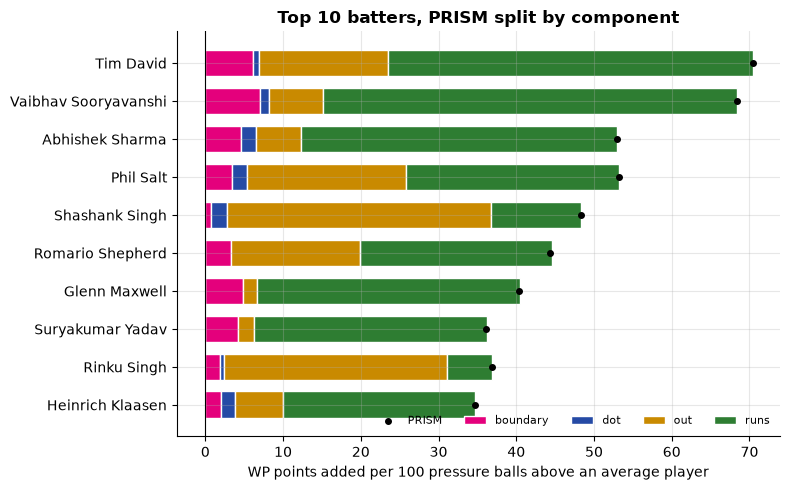

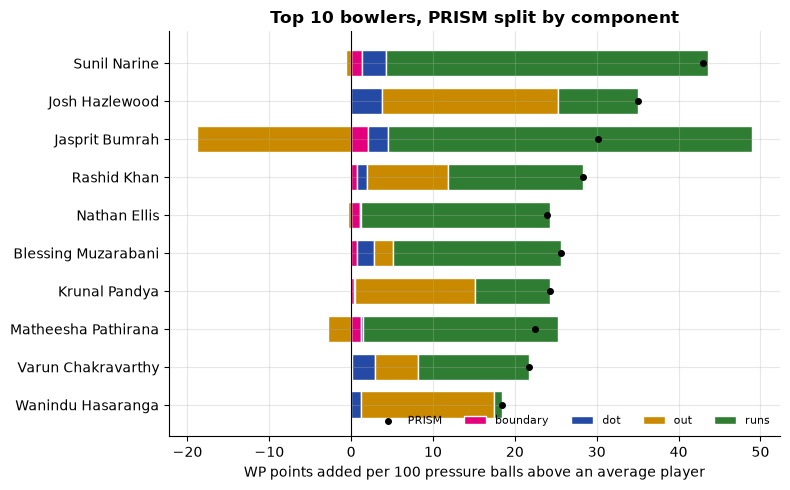

In [4]:
p6.components("bat"); plt.show()
p6.components("bowl"); plt.show()

## Step 4. Reserves for the Unstop name check

In [5]:
display(pd.read_csv(ROOT / "final_rankings" / "reserves_batters.csv")[["rank", "player_name", "teams", "median_rank"]])
pd.read_csv(ROOT / "final_rankings" / "reserves_bowlers.csv")[["rank", "player_name", "teams", "median_rank"]]

,rank,player_name,teams,median_rank
0,11,Nicholas Pooran,"Lucknow Super Giants, West Indies, Sunrisers H...",16.0
1,12,Harry Brook,"England, Sunrisers Hyderabad",16.0
2,13,Rashid Khan,"Afghanistan, Gujarat Titans",17.0


,rank,player_name,teams,median_rank
0,11,Mustafizur Rahman,"Bangladesh, Delhi Capitals, Chennai Super Kings",17.0
1,12,Abbas Afridi,"Pakistan, Pakistan A",17.0
2,13,Kuldeep Yadav,"Delhi Capitals, India",18.0


## Step 5. Sanity checks on names, shared names and players in both lists

In [6]:
both = set(tb.player_id) & set(tw.player_id)
print("players in both lists", [tb.set_index("player_id").loc[p, "player_name"] for p in both])
print("duplicate names in lists", tb.player_name.duplicated().any(), tw.player_name.duplicated().any())
print("all eligible and distinct", len(set(tb.player_id)) == 10, len(set(tw.player_id)) == 10)

players in both lists []
duplicate names in lists False False
all eligible and distinct True True


## Step 6. Raw pressure stats next to PRISM for familiarity

In [7]:
for role, t in (("bat", tb), ("bowl", tw)):
    r = read_parquet("player_ratings", f"player_ratings_{role}.parquet").set_index("player_id").loc[t.player_id]
    cols = ["sr_P", "sr_N", "avg_P", "dot_P", "bnd_P"] if role == "bat" else ["econ_P", "econ_N", "avg_P", "dot_P", "bnd_P"]
    display(r[["player_name"] + cols].round(2))

,player_name,sr_P,sr_N,avg_P,dot_P,bnd_P
player_id,,,,,,
6396,Tim David,198.19,168.50,36.44,0.28,0.28
50284,Vaibhav Sooryavanshi,241.75,218.43,62.25,0.34,0.42
6281,Abhishek Sharma,187.85,186.70,54.82,0.31,0.31
5553,Phil Salt,157.39,173.08,45.25,0.32,0.24
2756,Shashank Singh,189.68,155.01,79.67,0.20,0.26
6726,Romario Shepherd,145.03,158.94,20.67,0.38,0.20
838,Glenn Maxwell,162.37,160.17,24.23,0.32,0.24
1699,Suryakumar Yadav,171.21,165.27,33.48,0.29,0.26
4708,Rinku Singh,168.87,147.56,54.25,0.26,0.25


,player_name,econ_P,econ_N,avg_P,dot_P,bnd_P
player_id,,,,,,
781,Sunil Narine,6.43,6.88,18.56,0.38,0.10
830,Josh Hazlewood,7.85,8.40,13.91,0.42,0.18
2933,Jasprit Bumrah,8.05,7.04,29.44,0.36,0.17
4722,Rashid Khan,8.03,7.31,18.41,0.32,0.15
7920,Nathan Ellis,9.06,7.91,18.53,0.30,0.18
6523,Blessing Muzarabani,8.72,7.19,22.42,0.34,0.19
4219,Krunal Pandya,5.97,8.20,12.76,0.35,0.08
8661,Matheesha Pathirana,9.51,8.61,24.39,0.28,0.16
6256,Varun Chakravarthy,7.63,8.09,16.86,0.36,0.15


## Key findings

In [8]:
display(Markdown(f'''
- Batters, {", ".join(tb.player_name)}.
- Bowlers, {", ".join(tw.player_name)}.
- {int(tb.robust_badge.sum())} batters and {int(tw.robust_badge.sum())} bowlers hold a robust badge, top 10 in at least 80 percent of variants.
- Median P top 10 is {tb.p_top10.median():.0%} for batters and {tw.p_top10.median():.0%} for bowlers, places 6 to 10 are close and the intervals say so.
- Limitations, first innings leverage is compressed, DLS matches excluded, clutch barely repeats so the list mostly rewards skill in high-stakes states.
'''))


- Batters, Tim David, Vaibhav Sooryavanshi, Abhishek Sharma, Phil Salt, Shashank Singh, Romario Shepherd, Glenn Maxwell, Suryakumar Yadav, Rinku Singh, Heinrich Klaasen.
- Bowlers, Sunil Narine, Josh Hazlewood, Jasprit Bumrah, Rashid Khan, Nathan Ellis, Blessing Muzarabani, Krunal Pandya, Matheesha Pathirana, Varun Chakravarthy, Wanindu Hasaranga.
- 6 batters and 7 bowlers hold a robust badge, top 10 in at least 80 percent of variants.
- Median P top 10 is 61% for batters and 51% for bowlers, places 6 to 10 are close and the intervals say so.
- Limitations, first innings leverage is compressed, DLS matches excluded, clutch barely repeats so the list mostly rewards skill in high-stakes states.


## Outputs written

final_rankings, top10_batters.csv, top10_bowlers.csv, full_*.csv, reserves_*.csv, run_log.json, figures 09_components_*.png.